# Blends: silos, misturadora obrigatória e porto seco (instâncias pequenas)

**Disciplina:** GCC118 Programação Matemática, Fases 2 e 3 (modelo PLI, testes em solver e heurística).

Este notebook valida o modelo descrito em `03_modelo_PLI_blends.md`:

- cada rota produz **um lote de blend**: `garagem → silos (tipos do blend) → misturadora → porto seco → garagem`;
- a composição é exata: do tipo \(k\) retira-se \(\pi_k\,W\) toneladas, de um ou mais silos;
- o solver escolhe os silos, as quantidades, a ordem, a misturadora e o porto seco.

> **Aviso importante.** As instâncias de `make_blend_instance` são **SINTÉTICAS**: coordenadas em km num plano, com fator de circuidade 1,39 e diesel de R\$ 6,01/L, ambos medidos na Fase 1. Estoques, tarifas, silos, misturadoras e janelas são inventados, só para validar o modelo. A instância de `make_semireal_instance` usa a **rede real** da Fase 1 (municípios do Sul de Minas, recintos alfandegados de MG, matriz OSRM e diesel da ANP), mas os parâmetros de blend continuam **sintéticos**.

## 1. Dependências e código

In [1]:
import importlib, time
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import cafe_blend, cafe_blend_heur
importlib.reload(cafe_blend); importlib.reload(cafe_blend_heur)
from cafe_blend import (make_blend_instance, make_semireal_instance, solve_blend, evaluate, brute_force,
                        describe, plot_blend, need_of)
from cafe_blend_heur import construct, local_search, ils
pd.set_option('display.width', 160)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'axes.axisbelow': True})
AZUL, LARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'

def dados_silos(inst):
    return pd.DataFrame([dict(silo=inst['nomes'][s], tipo=inst['rotulo_tipo'][inst['tipo'][s]],
                              estoque_t=inst['e'][s], tarifa_R_t=inst['p'][s],
                              janela=f"{inst['janela'][s][0]:.1f}-{inst['janela'][s][1]:.1f} h") for s in inst['S']])

def custos(inst, sol):
    ev = evaluate(inst, sol)
    return {k: round(v, 1) for k, v in ev['components'].items()} | {'total': round(ev['cost'], 1), 'viavel': ev['feasible']}

## 2. Nível B1 (mínimo): 1 blend, 1 misturadora, 1 silo por tipo, 2 portos secos

Blend de exemplo: 10% tipo 2, 25% tipo 4 e 65% tipo 8, com lote \(W = 19{,}2\) t (1 contêiner). Com um silo por tipo, as retiradas são fixas e o modelo decide só a **ordem dos silos** e o **porto seco**. A força bruta enumera todas as ordens × portos e serve de prova de correção.

SINTETICA | blend: {'tipo 2': 0.1, 'tipo 4': 0.25, 'tipo 8': 0.65} | demanda por tipo (t): {'tipo 2': 1.92, 'tipo 4': 4.8, 'tipo 8': 12.48}


,silo,tipo,estoque_t,tarifa_R_t,janela
0,S1,tipo 2,2.4,22.6,0.0-14.0 h
1,S2,tipo 4,6.1,35.2,0.0-14.0 h
2,S3,tipo 8,21.9,16.0,0.0-14.0 h


PLI: Optimal | custo R$ 3070.63 | 0.12 s | binárias 20 | restrições 46
Força bruta: R$ 3070.63  ->  diferença 9.09e-13
lote 0: G -> S2[tipo 4: 4.80 t] -> S3[tipo 8: 12.48 t] -> S1[tipo 2: 1.92 t] -> M1 -> D1 -> G


,veiculo,deslocamento,aquisicao,misturadora,porto,atraso,total,viavel
0,350.0,1986.6,412.0,202.0,120.0,0.0,3070.6,True


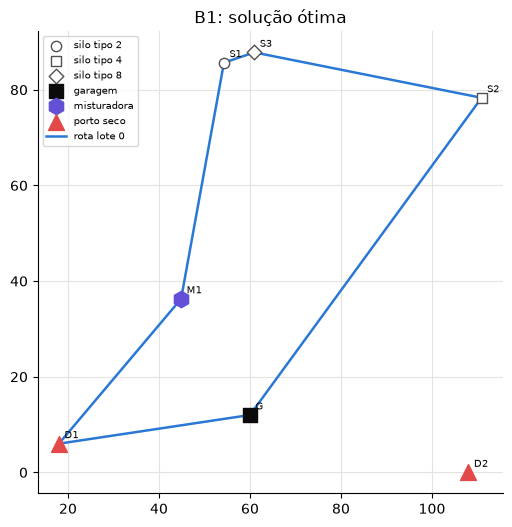

In [2]:
inst1 = make_blend_instance(n_types=3, silos_per_type=1, n_mix=1, n_ports=2, seed=11)
print(inst1['sintetica'], '| blend:', {inst1['rotulo_tipo'][k]: p for k, p in inst1['lots'][0]['pi'].items()},
      '| demanda por tipo (t):', {inst1['rotulo_tipo'][k]: round(v, 2) for k, v in need_of(inst1, inst1['lots'][0]).items()})
display(dados_silos(inst1))
r1 = solve_blend(inst1, time_limit=30)
bf, sol_bf = brute_force(inst1)
print(f"PLI: {r1['status']} | custo R$ {r1['obj']:.2f} | {r1['time']:.2f} s | binárias {r1['n_bin']} | restrições {r1['n_cons']}")
print(f"Força bruta: R$ {bf:.2f}  ->  diferença {abs(bf - r1['obj']):.2e}")
print(*describe(inst1, r1['sol']), sep='\n')
display(pd.DataFrame([custos(inst1, r1['sol'])]))
plot_blend(inst1, r1['sol'], 'B1: solução ótima'); plt.show()

## 3. Nível B2: vários silos por tipo (Traveling Purchaser Problem)

Agora cada tipo está em 3 silos, com estoque e tarifa de expedição diferentes. O modelo troca deslocamento por tarifa: vale a pena ir a um silo mais distante se ele for mais barato, ou se um só silo não tiver estoque suficiente.

,silo,tipo,estoque_t,tarifa_R_t,janela
0,S1,tipo 2,2.2,21.0,0.0-14.0 h
1,S2,tipo 2,1.3,15.8,0.0-14.0 h
2,S3,tipo 2,1.5,26.6,0.0-14.0 h
3,S4,tipo 4,5.0,31.0,0.0-14.0 h
4,S5,tipo 4,6.9,27.5,0.0-14.0 h
5,S6,tipo 4,5.4,31.6,0.0-14.0 h
6,S7,tipo 8,13.2,39.9,0.0-14.0 h
7,S8,tipo 8,11.0,36.0,0.0-14.0 h
8,S9,tipo 8,19.9,32.7,0.0-14.0 h


Optimal | custo R$ 3459.36 | 0.78 s | binárias 104
lote 0: G -> S4[tipo 4: 4.80 t] -> S7[tipo 8: 12.48 t] -> S1[tipo 2: 1.92 t] -> M1 -> D2 -> G


,veiculo,deslocamento,aquisicao,misturadora,porto,atraso,total,viavel
0,350.0,2222.3,687.1,140.0,60.0,0.0,3459.4,True


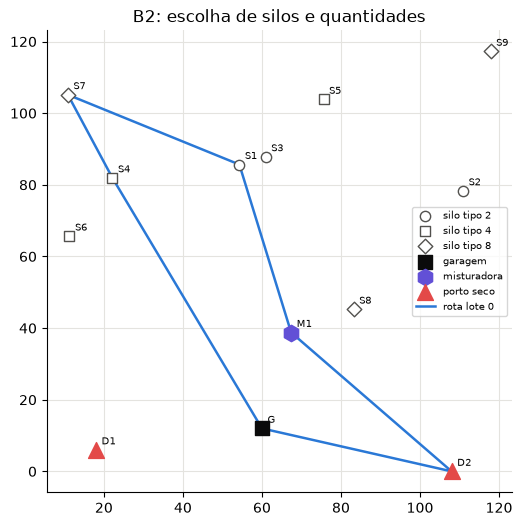

In [3]:
inst2 = make_blend_instance(n_types=3, silos_per_type=3, n_mix=1, n_ports=2, seed=11)
display(dados_silos(inst2))
r2 = solve_blend(inst2, time_limit=60)
print(f"{r2['status']} | custo R$ {r2['obj']:.2f} | {r2['time']:.2f} s | binárias {r2['n_bin']}")
print(*describe(inst2, r2['sol']), sep='\n')
display(pd.DataFrame([custos(inst2, r2['sol'])]))
plot_blend(inst2, r2['sol'], 'B2: escolha de silos e quantidades'); plt.show()

**Sensibilidade à dispersão das tarifas.** Com tarifas iguais, o modelo minimiza só o deslocamento. Quanto maior a diferença de tarifa entre silos, mais ele aceita desvios para comprar mais barato.

In [4]:
linhas = []
for faixa in [(25, 25), (20, 30), (10, 40), (0, 80)]:
    inst = make_blend_instance(n_types=3, silos_per_type=3, seed=11, price=faixa)
    r = solve_blend(inst, time_limit=60); ev = evaluate(inst, r['sol'])
    rota = r['sol']['lots'][0]['route']
    linhas.append(dict(tarifa_R_t=f'{faixa[0]}-{faixa[1]}', silos_visitados=len(rota) - 4,
                       km=round(sum(inst['dist'][i][j] for i, j in zip(rota[:-1], rota[1:])), 1),
                       deslocamento=round(ev['components']['deslocamento'], 1),
                       tarifas=round(ev['components']['aquisicao'], 1), total=round(ev['cost'], 1)))
display(pd.DataFrame(linhas))

,tarifa_R_t,silos_visitados,km,deslocamento,tarifas,total
0,25-25,3,427.0,2222.3,480.0,3252.3
1,20-30,3,427.0,2222.3,544.1,3316.4
2,10-40,3,427.0,2222.3,671.3,3443.6
3,0-80,4,478.6,2490.6,924.5,3965.1


**Leitura.** Com tarifas iguais ou pouco dispersas, a rota não muda (3 silos, 427 km); só o custo de compra varia. Com tarifas entre R\$ 0 e R\$ 80/t, o modelo passa a visitar um quarto silo e roda 52 km a mais, porque o desvio é compensado por tarifas menores. Esse é o trade-off típico do *Traveling Purchaser Problem*.

## 4. Nível B3: escolha da misturadora

Com duas misturadoras candidatas, o solver escolhe uma. A tabela compara a solução ótima com as soluções obtidas fixando cada misturadora.

,caso,misturadora,porto,custo
0,livre (ótimo),M1,D1,3486.1
1,"fixa em M1 (F=248, σ=1.7 h)",M1,D1,3486.1
2,"fixa em M2 (F=245, σ=1.6 h)",M2,D2,3643.8


lote 0: G -> S2[tipo 2: 1.20 t] -> S5[tipo 8: 12.48 t] -> S3[tipo 4: 3.80 t] -> S1[tipo 2: 0.72 t] -> S4[tipo 4: 1.00 t] -> M1 -> D1 -> G


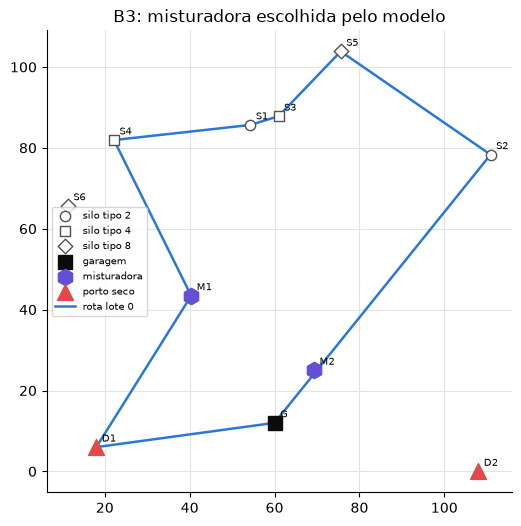

In [5]:
inst3 = make_blend_instance(n_types=3, silos_per_type=2, n_mix=2, n_ports=2, seed=11)
r3 = solve_blend(inst3, time_limit=60)
linhas = [dict(caso='livre (ótimo)', misturadora=inst3['nomes'][r3['sol']['lots'][0]['route'][-3]],
               porto=inst3['nomes'][r3['sol']['lots'][0]['route'][-2]], custo=round(r3['obj'], 1))]
for m in inst3['M']:
    fixa = dict(inst3, M=[m])
    rf = solve_blend(fixa, time_limit=60)
    linhas.append(dict(caso=f"fixa em {inst3['nomes'][m]} (F={inst3['F_mix'][m]:.0f}, σ={inst3['serv'][m]} h)",
                       misturadora=inst3['nomes'][m], porto=inst3['nomes'][rf['sol']['lots'][0]['route'][-2]],
                       custo=round(rf['obj'], 1)))
display(pd.DataFrame(linhas))
print(*describe(inst3, r3['sol']), sep='\n')
plot_blend(inst3, r3['sol'], 'B3: misturadora escolhida pelo modelo'); plt.show()

**Leitura.** A misturadora M1 é a escolhida. Fixar M2 custa R\$ 157,70 a mais: a rota muda de porto seco (D1 → D2), e a soma de desvio, uso da misturadora e entrada no terminal fica maior.

## 5. Nível B4: janelas de tempo (TSPTW)

Os silos têm horário de expedição (janela dura), a misturadora atende entre 1 h e 11 h e o porto seco tem um *cut-off* flexível, com penalidade \(\beta\) = R\$ 200/h de atraso. A instância é a mesma do B3; só as janelas mudam.

In [6]:
inst4 = make_blend_instance(n_types=3, silos_per_type=2, n_mix=2, n_ports=2, seed=11, tw=True)
r4 = solve_blend(inst4, time_limit=60); ev4 = evaluate(inst4, r4['sol'])
display(dados_silos(inst4))
print('Sem janelas:', *describe(inst3, r3['sol']), f"custo R$ {r3['obj']:.2f}")
print('Com janelas:', *describe(inst4, r4['sol']), f"custo R$ {r4['obj']:.2f}")
T = ev4['lots'][0]['T']
display(pd.DataFrame([dict(no=inst4['nomes'][i], inicio_servico_h=round(t, 2), janela=f"{inst4['janela'][i][0]:.1f}-{inst4['janela'][i][1]:.1f}")
                      for i, t in T.items() if i != inst4['G']]))
print(f"Atraso no cut-off: {ev4['lots'][0]['late']:.2f} h | fim da rota: {ev4['lots'][0]['fim']:.2f} h (Tmax = {inst4['Tmax']} h)")

,silo,tipo,estoque_t,tarifa_R_t,janela
0,S1,tipo 2,1.5,28.2,1.5-5.5 h
1,S2,tipo 2,1.2,16.5,0.0-5.4 h
2,S3,tipo 4,3.8,15.8,1.0-6.2 h
3,S4,tipo 4,4.0,26.6,2.0-9.0 h
4,S5,tipo 8,13.0,28.0,0.0-6.1 h
5,S6,tipo 8,18.0,31.0,1.0-7.3 h


Sem janelas: lote 0: G -> S2[tipo 2: 1.20 t] -> S5[tipo 8: 12.48 t] -> S3[tipo 4: 3.80 t] -> S1[tipo 2: 0.72 t] -> S4[tipo 4: 1.00 t] -> M1 -> D1 -> G custo R$ 3486.10
Com janelas: lote 0: G -> S2[tipo 2: 1.20 t] -> S5[tipo 8: 12.48 t] -> S3[tipo 4: 3.80 t] -> S1[tipo 2: 0.72 t] -> S4[tipo 4: 1.00 t] -> M1 -> D1 -> G custo R$ 4097.57


,no,inicio_servico_h,janela
0,S2,1.94,0.0-5.4
1,S5,3.45,0.0-6.1
2,S3,4.45,1.0-6.2
3,S1,5.11,1.5-5.5
4,S4,6.36,2.0-9.0
5,M1,7.85,1.0-11.0
6,D1,10.56,0.0-7.5


Atraso no cut-off: 3.06 h | fim da rota: 12.04 h (Tmax = 14.0 h)


**Leitura.** A rota ótima é a mesma do B3, mas, com os horários de expedição dos silos, o caminhão chega ao porto seco 3,06 h depois do *cut-off*. A diferença de custo (R\$ 611,47) é exatamente a penalidade \(eta 	imes 3{,}06\) h. Antecipar a chegada exigiria outra sequência de silos, que fica mais cara do que o atraso.

## 6. Instância semi-real: rede da Fase 1 (Sul de Minas, OSRM, recintos de MG)

A garagem fica em Varginha. Os silos são 9 municípios produtores sorteados entre os 30 maiores do Sul/Sudoeste (3 tipos × 3 silos). As misturadoras ficam em Três Pontas e Alfenas, e os portos secos são os 5 recintos alfandegados de MG. Distâncias e tempos vêm do OSRM e o diesel é o P50 da ANP-MG. Estoques, tarifas e janelas são **sintéticos**.

SEMI-REAL (rede real, blends sinteticos) | diesel R$ 6.01/L


,silo,tipo,estoque_t,tarifa_R_t,janela
0,Guapé,tipo 2,17.5,21.5,0.5-5.0 h
1,Poço Fundo,tipo 2,25.2,38.6,1.5-6.3 h
2,Elói Mendes,tipo 2,26.0,15.6,2.0-8.5 h
3,Claraval,tipo 4,7.1,19.1,0.0-6.7 h
4,São Sebastião do Paraíso,tipo 4,5.0,22.2,2.0-8.1 h
5,Boa Esperança,tipo 4,5.0,36.7,1.0-7.5 h
6,Machado,tipo 8,22.5,36.1,2.0-6.6 h
7,Carmo da Cachoeira,tipo 8,20.9,23.4,1.5-7.3 h
8,Coqueiral,tipo 8,14.0,24.7,1.5-6.9 h


Exato: Optimal R$ 6672.74 em 36.4 s | ILS: R$ 6672.74 em 3.4 s
lote 0: Varginha -> Elói Mendes[tipo 2: 1.92 t] -> Boa Esperança[tipo 4: 4.80 t] -> Coqueiral[tipo 8: 12.48 t] -> Três Pontas -> CLIA Varginha -> Varginha
lote 1: Varginha -> Elói Mendes[tipo 2: 16.32 t] -> Machado[tipo 8: 1.92 t] -> São Sebastião do Paraíso[tipo 4: 0.96 t] -> Alfenas -> CLIA Varginha -> Varginha


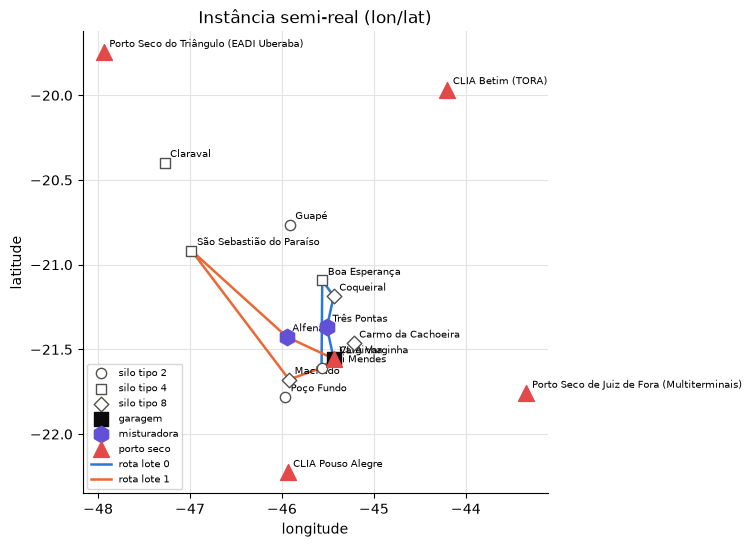

In [7]:
inst6 = make_semireal_instance(n_types=3, silos_per_type=3, n_lots=2, tw=True, seed=4)
print(inst6['sintetica'], f"| diesel R$ {inst6['diesel']:.2f}/L")
display(dados_silos(inst6))
r6 = solve_blend(inst6, time_limit=120)
h6 = ils(inst6, iters=300, time_limit=20, seed=1)
print(f"Exato: {r6['status']} R$ {r6['obj']:.2f} em {r6['time']:.1f} s | ILS: R$ {h6['cost']:.2f} em {h6['time']:.1f} s")
print(*describe(inst6, r6['sol']), sep='\n')
ax = plot_blend(inst6, r6['sol'], 'Instância semi-real (lon/lat)')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); plt.show()

## 7. Escalabilidade do modelo exato (Fase 2) e heurística (Fase 3)

Instâncias sintéticas crescentes, com janelas de tempo, limite de 30 s no solver (CBC) e até 20 s na ILS. O gap do exato vem do log do CBC; o gap da ILS é medido contra a melhor solução conhecida.

In [8]:
grade = [(3, 1, 1, 1), (4, 1, 1, 1), (5, 1, 1, 1), (3, 2, 2, 1), (3, 3, 2, 1), (4, 3, 2, 1),
         (3, 2, 2, 2), (4, 3, 2, 2), (4, 4, 3, 2), (4, 4, 3, 3)]
linhas = []
for (nt, spt, nm, nl) in grade:
    inst = make_blend_instance(n_types=nt, silos_per_type=spt, n_mix=nm, n_ports=3, n_lots=nl, tw=True, seed=7)
    ex = solve_blend(inst, time_limit=30)
    h = ils(inst, iters=300, time_limit=20, seed=1)
    melhor = min(h['cost'], ex.get('obj') or np.inf)
    linhas.append(dict(tipos=nt, silos_por_tipo=spt, misturadoras=nm, lotes=nl, binarias=ex['n_bin'],
                       variaveis=ex['n_vars'], restricoes=ex['n_cons'], status=ex['status'],
                       custo_exato=round(ex['obj'], 1) if ex.get('obj') else None, tempo_exato_s=round(ex['time'], 2),
                       gap_exato_pct=None if ex.get('gap') is None else round(100 * ex['gap'], 1),
                       custo_ils=round(h['cost'], 1), tempo_ils_s=round(h['time'], 2),
                       gap_ils_pct=round(100 * (h['cost'] / melhor - 1), 2)))
esc = pd.DataFrame(linhas); display(esc)
esc.to_csv('escalabilidade_blends.csv', index=False)

,tipos,silos_por_tipo,misturadoras,lotes,binarias,variaveis,restricoes,status,custo_exato,tempo_exato_s,gap_exato_pct,custo_ils,tempo_ils_s,gap_ils_pct
0,3,1,1,1,22,36,50,Optimal,2550.1,0.07,0.0,2550.1,0.20,0.0
1,4,1,1,1,31,48,69,Optimal,3490.9,0.22,0.0,3490.9,0.42,0.0
2,5,1,1,1,42,62,92,Optimal,3254.3,0.49,0.0,3254.3,0.80,0.0
3,3,2,2,1,65,89,128,Optimal,2873.0,0.35,0.0,2873.0,0.83,0.0
4,3,3,2,1,119,152,233,Optimal,2719.3,1.00,0.0,2719.3,1.10,0.0
5,4,3,2,1,191,233,375,Optimal,3589.2,21.76,0.0,3589.2,3.48,0.0
6,3,2,2,2,130,178,262,Optimal,5244.9,0.82,0.0,5244.9,1.45,0.0
7,4,3,2,2,382,466,762,Feasible,7574.1,29.87,40.8,6509.4,4.16,0.0
8,4,4,3,2,670,780,1298,Not Solved,NaN,29.57,NaN,5382.4,8.50,0.0
9,4,4,3,3,1005,1170,1939,Not Solved,NaN,29.26,NaN,7712.0,10.26,0.0


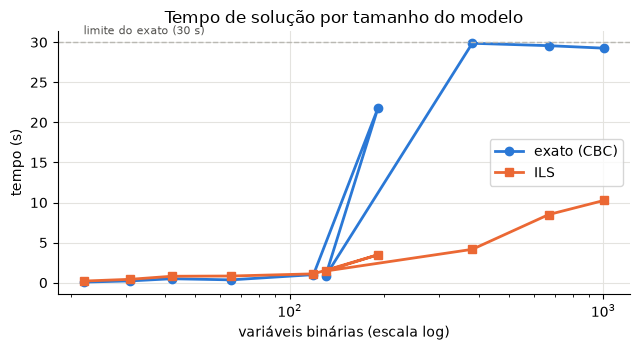

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(esc['binarias'], esc['tempo_exato_s'], 'o-', color=AZUL, lw=2, label='exato (CBC)')
ax.plot(esc['binarias'], esc['tempo_ils_s'], 's-', color=LARANJA, lw=2, label='ILS')
ax.axhline(30, ls='--', color='#b9b8b2', lw=1); ax.text(esc['binarias'].min(), 31, 'limite do exato (30 s)', fontsize=8, color='#52514e')
ax.set_xscale('log'); ax.set_xlabel('variáveis binárias (escala log)'); ax.set_ylabel('tempo (s)')
ax.set_title('Tempo de solução por tamanho do modelo'); ax.legend(); plt.tight_layout(); plt.show()

**Leitura.** O exato prova o ótimo até 191 binárias (4 tipos × 3 silos, 1 lote), já gastando cerca de 22 s. Com 382 binárias (2 lotes), para no limite com gap de 40,8% e custo 16% acima do da ILS. A partir de 670 binárias, não encontra solução viável em 30 s. Onde o ótimo é conhecido, a ILS o reproduz (`gap_ils_pct = 0`); nas demais linhas, o gap da ILS é medido contra a melhor solução conhecida, que é a própria ILS.

## 8. Gráfico obrigatório: heurística × exato (qualidade × tempo)

Na maior instância da grade, o exato roda com limites de tempo crescentes. Cada ponto é a melhor solução que ele tem quando o tempo acaba, ou nenhuma, se ainda não achou. A curva da ILS é o histórico da melhor solução ao longo do tempo. O custo está relativo à melhor solução conhecida.

,solver,limite_s,tempo_s,custo,gap,status
0,cbc,5,4.364465,NaN,NaN,Not Solved
1,highs,5,5.092586,8036.791466,0.100963,Feasible
2,cbc,15,14.379085,NaN,NaN,Not Solved
3,highs,15,15.093823,8036.791466,0.100792,Feasible
4,cbc,30,29.398961,NaN,NaN,Not Solved
5,highs,30,30.090726,8036.791466,0.100792,Feasible
6,cbc,60,59.378969,NaN,NaN,Not Solved
7,highs,60,60.092653,8036.791466,0.092645,Feasible


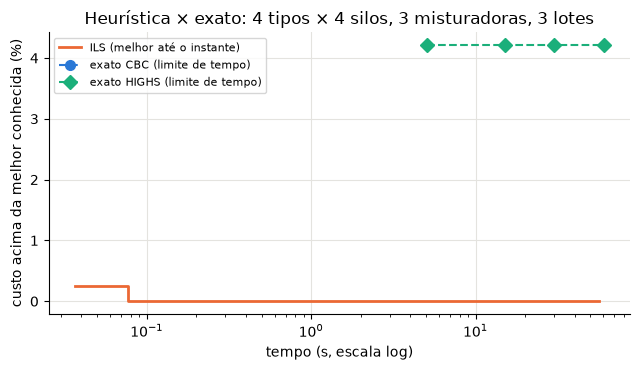

Movimentos de melhoria da busca local: {'add': 501, 'swap-source': 1157, '2opt': 3911, 'mixer': 967, 'relocate': 114, 'drop': 27}


In [10]:
instG = make_blend_instance(n_types=4, silos_per_type=4, n_mix=3, n_ports=3, n_lots=3, tw=True, seed=7)
hG = ils(instG, iters=2000, time_limit=60, seed=1)
pts = []
for lim in [5, 15, 30, 60]:
    for sn in ['cbc', 'highs']:
        e = solve_blend(instG, time_limit=lim, solver_name=sn)
        pts.append(dict(solver=sn, limite_s=lim, tempo_s=e['time'], custo=e.get('obj'), gap=e.get('gap'), status=e['status']))
pts = pd.DataFrame(pts); display(pts)
ref = min(hG['cost'], pts['custo'].min(skipna=True))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ht = np.array(hG['history'])
ax.step(ht[:, 0], 100 * (ht[:, 1] / ref - 1), where='post', color=LARANJA, lw=2, label='ILS (melhor até o instante)')
for sn, cor, mk in [('cbc', AZUL, 'o'), ('highs', AQUA, 'D')]:
    p = pts[(pts['solver'] == sn) & pts['custo'].notna()]
    ax.plot(p['tempo_s'], 100 * (p['custo'] / ref - 1), mk + '--', color=cor, lw=1.5, ms=7, label=f'exato {sn.upper()} (limite de tempo)')
ax.set_xscale('log'); ax.set_xlabel('tempo (s, escala log)'); ax.set_ylabel('custo acima da melhor conhecida (%)')
ax.set_title(f"Heurística × exato: 4 tipos × 4 silos, 3 misturadoras, 3 lotes")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print('Movimentos de melhoria da busca local:', hG['stats'])

**Leitura.** Nesta instância (1.005 binárias), o CBC não encontrou **nenhuma solução viável** em nenhum dos limites testados (até 60 s), por isso não há pontos dele no gráfico. O HiGHS acha uma solução em 5 s, mas ela fica 4,2% acima da melhor conhecida e não melhora até 60 s (gap de 9,3% no fim). A ILS chega à melhor solução conhecida em menos de 0,1 s. Isso caracteriza o ponto a partir do qual a heurística é necessária, como pede o enunciado.

## 9. Próximos passos

1. Fase 2: trocar a grade sintética pela instância semi-real com mais silos e lotes, e testar a decomposição em dois estágios (seleção de silos por PL e depois roteamento).
2. Fase 3: acrescentar à ILS um movimento entre lotes (transferir retiradas de um silo disputado) e comparar com o exato em mais sementes.
3. Fase 4: cenários de diesel (P10/P50/P90 da Fase 1), variação de estoques (bienalidade) e de janelas, medindo a robustez da solução.